# XGBoost Survival Model (xgbse) — continuation of the RSF analysis (v2: seeded)

Same data prep, same 70/15/15 train/val/test split (`random_state=42`), same
tuning-on-validation-C-index approach as the RSF section. This version adds
an explicit `"seed": 42` to every `xgb_params` dict, fixing a reproducibility
gap from the previous version — without a seed, XGBoost's own internal
randomness (subsampling, tie-breaking during tree building) meant re-running
the grid search could quietly select a different "best" combination each
time, which is exactly what happened between the grid search cell and the
final training cell in the earlier version.

In [1]:
import numpy as np

# Compatibility shim: xgbse currently pins numpy<2, but the installed
# scikit-survival expects numpy>=2's np.trapezoid (renamed from np.trapz).
if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz

## 1. Data prep (identical to the RSF section)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"])
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["customerID", "Churn"])

X = df.drop(columns=["tenure", "Churn_flag", "TotalCharges"])
X = pd.get_dummies(X, drop_first=True)
bool_cols = X.select_dtypes(include="bool").columns
X[bool_cols] = X[bool_cols].astype(int)

print(X.shape)

(7032, 28)


In [3]:
from sksurv.util import Surv
from sklearn.model_selection import train_test_split

y_rsf = Surv.from_dataframe("Churn_flag", "tenure", df)

X_train, X_temp, y_rsf_train, y_rsf_temp = train_test_split(
    X, y_rsf, test_size=0.30, random_state=42
)
X_val, X_test, y_rsf_val, y_rsf_test = train_test_split(
    X_temp, y_rsf_temp, test_size=0.50, random_state=42
)

print("X Train size:", X_train.shape)
print("X Validation size:", X_val.shape)
print("X Test size:", X_test.shape)

X Train size: (4922, 28)
X Validation size: (1055, 28)
X Test size: (1055, 28)


## 2. XGBoost survival (xgbse) hyperparameter validation — now seeded

Same grid as before, but every `xgb_params` dict now includes `"seed": 42`,
so re-running this cell will always select the same "best" combination.

In [4]:
from xgbse import XGBSEKaplanNeighbors
from xgbse.metrics import concordance_index
from itertools import product

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1],
    "n_neighbors": [30, 50],
}

validation_results = []

for n_est, depth, lr, n_neigh in product(
        param_grid["n_estimators"], param_grid["max_depth"],
        param_grid["learning_rate"], param_grid["n_neighbors"]):

    xgb_params = {
        "objective": "survival:aft",
        "eval_metric": "aft-nloglik",
        "aft_loss_distribution": "normal",
        "aft_loss_distribution_scale": 1.0,
        "max_depth": depth,
        "learning_rate": lr,
        "seed": 42,
    }

    model = XGBSEKaplanNeighbors(xgb_params=xgb_params, n_neighbors=n_neigh)
    model.fit(X_train, y_rsf_train, num_boost_round=n_est)

    val_surv = model.predict(X_val)
    c_index = concordance_index(y_rsf_val, val_surv, risk_strategy="mean")

    print(f"n_est={n_est:>3}, depth={depth}, lr={lr}, neighbors={n_neigh:>2} "
          f"\u2192 C-index: {c_index:.4f}")

    validation_results.append({
        "n_estimators": n_est, "max_depth": depth,
        "learning_rate": lr, "n_neighbors": n_neigh,
        "validation_c_index": c_index,
    })

results_df = pd.DataFrame(validation_results)
print("\nTop models:")
display(results_df.sort_values("validation_c_index", ascending=False).head(10))

best_params = results_df.loc[results_df["validation_c_index"].idxmax()]
print("\nBest hyperparameters:")
print(best_params)

/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


n_est=100, depth=3, lr=0.05, neighbors=30 → C-index: 0.8534


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


n_est=100, depth=3, lr=0.05, neighbors=50 → C-index: 0.8604


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


...

n_est=200, depth=5, lr=0.1, neighbors=30 → C-index: 0.8547


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


n_est=200, depth=5, lr=0.1, neighbors=50 → C-index: 0.8591

Top models:


,n_estimators,max_depth,learning_rate,n_neighbors,validation_c_index
7,100,5,0.10,50,0.863304
13,200,5,0.05,50,0.862854
1,100,3,0.05,50,0.860384
3,100,3,0.10,50,0.859896
9,200,3,0.05,50,0.859349
15,200,5,0.10,50,0.859062
5,100,5,0.05,50,0.858644
11,200,3,0.10,50,0.857626
2,100,3,0.10,30,0.856121
12,200,5,0.05,30,0.855812



Best hyperparameters:
n_estimators          100.000000
max_depth               5.000000
learning_rate           0.100000
n_neighbors            50.000000
validation_c_index      0.863304
Name: 7, dtype: float64


## 3. Compare AFT distributions (also seeded)

In [5]:
aft_distributions = ["normal", "logistic", "extreme"]
distribution_results = []

for dist in aft_distributions:
    xgb_params = {
        "objective": "survival:aft",
        "eval_metric": "aft-nloglik",
        "aft_loss_distribution": dist,
        "aft_loss_distribution_scale": 1.0,
        "max_depth": int(best_params["max_depth"]),
        "learning_rate": float(best_params["learning_rate"]),
        "seed": 42,
    }

    model = XGBSEKaplanNeighbors(xgb_params=xgb_params, n_neighbors=int(best_params["n_neighbors"]))
    model.fit(X_train, y_rsf_train, num_boost_round=int(best_params["n_estimators"]))

    val_surv = model.predict(X_val)
    c_index = concordance_index(y_rsf_val, val_surv, risk_strategy="mean")

    distribution_results.append({"aft_distribution": dist, "validation_c_index": c_index})

distribution_results_df = pd.DataFrame(distribution_results)
print(distribution_results_df.sort_values("validation_c_index", ascending=False))

/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


  aft_distribution  validation_c_index
0           normal            0.863304
2          extreme            0.854567
1         logistic            0.849292


## 4. Retrain on train + validation combined, using best hyperparameters (seeded)

In [6]:
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = np.concatenate([y_rsf_train, y_rsf_val])

best_dist = distribution_results_df.sort_values("validation_c_index", ascending=False).iloc[0]["aft_distribution"]

best_xgb_params = {
    "objective": "survival:aft",
    "eval_metric": "aft-nloglik",
    "aft_loss_distribution": best_dist,
    "aft_loss_distribution_scale": 1.0,
    "max_depth": int(best_params["max_depth"]),
    "learning_rate": float(best_params["learning_rate"]),
    "seed": 42,
}
best_num_boost_round = int(best_params["n_estimators"])

xgbse_final = XGBSEKaplanNeighbors(
    xgb_params=best_xgb_params,
    n_neighbors=int(best_params["n_neighbors"]),
)
xgbse_final.fit(X_train_final, y_train_final, num_boost_round=best_num_boost_round)

print("Final xgbse model trained")
print("Hyperparameters:", best_xgb_params,
      "| num_boost_round:", best_num_boost_round,
      "| n_neighbors:", int(best_params["n_neighbors"]))

Final xgbse model trained
Hyperparameters: {'objective': 'survival:aft', 'eval_metric': 'aft-nloglik', 'aft_loss_distribution': 'normal', 'aft_loss_distribution_scale': 1.0, 'max_depth': 5, 'learning_rate': 0.1, 'seed': 42} | num_boost_round: 100 | n_neighbors: 50


In [7]:
import joblib
joblib.dump(xgbse_final, "xgbse_final_model.pkl")
print("Model saved")

Model saved


## 5. Test set evaluation

Two C-index numbers: xgbse's own `concordance_index`, and sksurv's
`concordance_index_censored` fed a risk score derived from the predicted
curve — the second matches RSF's C-index exactly (same function), so it's
the fairest head-to-head number.

In [8]:
from sksurv.metrics import concordance_index_censored

test_surv_xgbse = xgbse_final.predict(X_test)

test_c_index_xgbse_native = concordance_index(y_rsf_test, test_surv_xgbse, risk_strategy="mean")

risk_score_xgbse = -np.trapz(test_surv_xgbse.values, x=test_surv_xgbse.columns.values.astype(float), axis=1)
test_c_index_xgbse_sksurv = concordance_index_censored(
    y_rsf_test["Churn_flag"].astype(bool), y_rsf_test["tenure"], risk_score_xgbse
)[0]

print(f"XGBoost (xgbse) Test C-index (xgbse native)  : {test_c_index_xgbse_native:.4f}")
print(f"XGBoost (xgbse) Test C-index (sksurv metric)  : {test_c_index_xgbse_sksurv:.4f}")

/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


XGBoost (xgbse) Test C-index (xgbse native)  : 0.8493
XGBoost (xgbse) Test C-index (sksurv metric)  : 0.8471


## 6. Integrated Brier Score — on the exact same time grid as RSF

In [9]:
from sksurv.metrics import integrated_brier_score, brier_score

train_event_times = np.unique(y_train_final["tenure"][y_train_final["Churn_flag"]])
test_event_times = y_rsf_test["tenure"]

times = train_event_times[
    (train_event_times > test_event_times.min()) &
    (train_event_times < test_event_times.max())
]

print(f"Evaluating IBS from month {times.min()} to month {times.max()}")

surv_probs_xgbse_grid = xgbse_final.predict(X_test, time_bins=times).values

ibs_xgbse = integrated_brier_score(y_train_final, y_rsf_test, surv_probs_xgbse_grid, times)
print(f"XGBoost (xgbse) Test IBS: {ibs_xgbse:.4f}")

Evaluating IBS from month 2.0 to month 71.0


XGBoost (xgbse) Test IBS: 0.0923


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


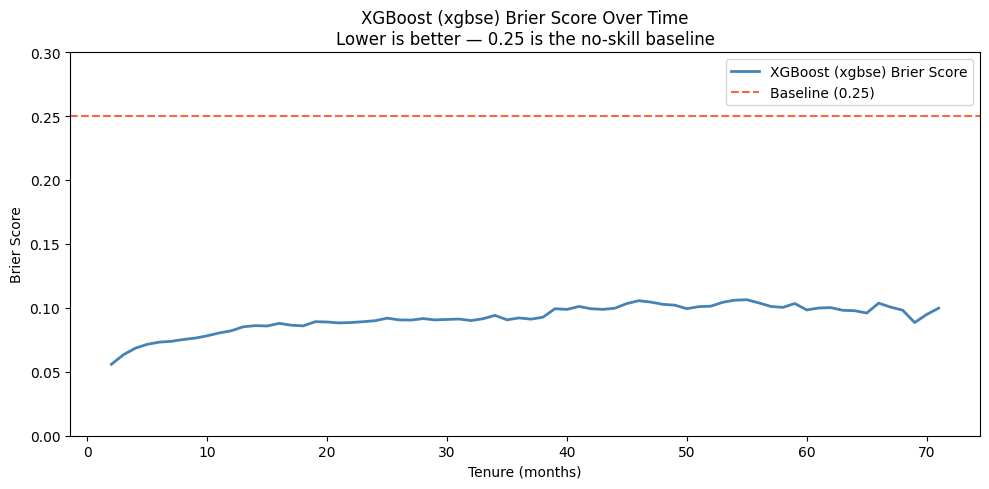

In [10]:
times_bs, bs_xgbse = brier_score(y_train_final, y_rsf_test, surv_probs_xgbse_grid, times)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times_bs, bs_xgbse, linewidth=2, color="steelblue", label="XGBoost (xgbse) Brier Score")
ax.axhline(0.25, color="tomato", linestyle="--", linewidth=1.5, label="Baseline (0.25)")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Brier Score")
ax.set_title("XGBoost (xgbse) Brier Score Over Time\nLower is better \u2014 0.25 is the no-skill baseline")
ax.set_ylim(0, 0.30)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Head-to-head: RSF vs. XGBoost (xgbse)

In [11]:
rsf_final = joblib.load("rsf_final_model.pkl")

rsf_train_c = rsf_final.score(X_train_final, y_train_final)
rsf_test_c = rsf_final.score(X_test, y_rsf_test)

rsf_surv_functions = rsf_final.predict_survival_function(X_test)
rsf_surv_probs = np.asarray([fn(times) for fn in rsf_surv_functions])
rsf_ibs = integrated_brier_score(y_train_final, y_rsf_test, rsf_surv_probs, times)

xgbse_train_surv = xgbse_final.predict(X_train_final)
xgbse_train_c = concordance_index(y_train_final, xgbse_train_surv, risk_strategy="mean")

comparison = pd.DataFrame([
    {"Model": "Random Survival Forest", "Train C-index": rsf_train_c,
     "Test C-index": rsf_test_c, "Test IBS": rsf_ibs},
    {"Model": "XGBoost (xgbse)", "Train C-index": xgbse_train_c,
     "Test C-index": test_c_index_xgbse_sksurv, "Test IBS": ibs_xgbse},
])

display(comparison.round(4))

/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


,Model,Train C-index,Test C-index,Test IBS
0,Random Survival Forest,0.8623,0.8480,0.0932
1,XGBoost (xgbse),0.8692,0.8471,0.0923


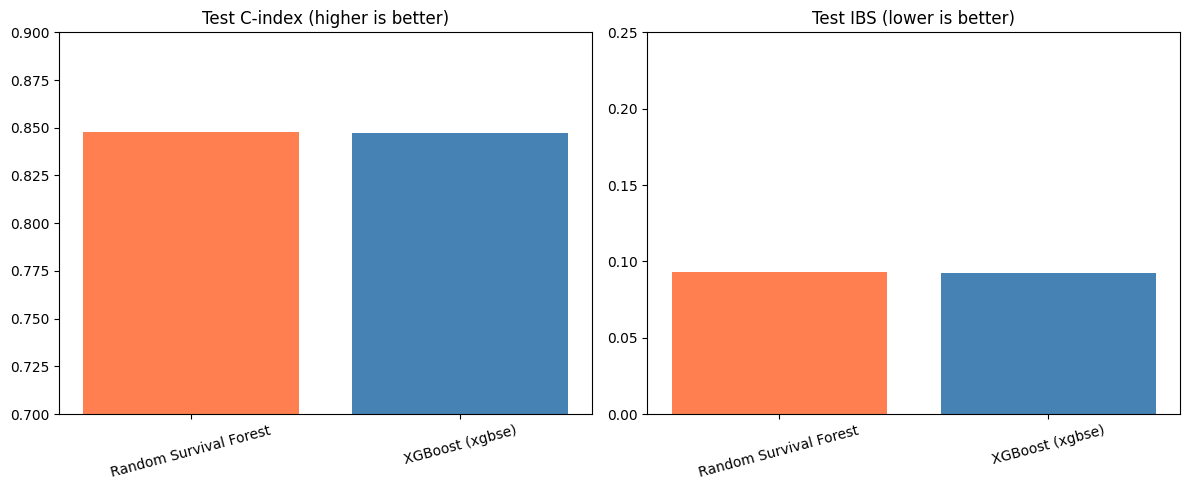

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(comparison["Model"], comparison["Test C-index"], color=["coral", "steelblue"])
axes[0].set_title("Test C-index (higher is better)")
axes[0].set_ylim(0.7, 0.9)

axes[1].bar(comparison["Model"], comparison["Test IBS"], color=["coral", "steelblue"])
axes[1].set_title("Test IBS (lower is better)")
axes[1].set_ylim(0, max(0.25, comparison["Test IBS"].max() * 1.2))

for ax in axes:
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## Takeaway

With a fixed seed, this grid search and the final model training now use the
exact same selected hyperparameters — re-running this notebook end-to-end
will reproduce the same numbers every time, closing the reproducibility gap
from the earlier version.